# Graph Features

The following demos how to generate molecular graphs. This code adapts the drawing modules from [MMGX](https://github.com/ohuelab/MMGX.git) and several features observed in [Chemprop](https://github.com/chemprop/chemprop.git). The goal is to allow users to not only be able to generate molecular graphs for graph modeling, but also to draw the molecular graphs in 2D for visual analysis.

In [1]:
import sys
import os
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

In [2]:
from mminer_graphs.graph import AtomGraph, GLOBAL_VALUES, PharmacophoreGraph, FunctionalGraph, JunctionTreeGraph, ClusterGraph
from mminer_graphs.visualizer import Graph

smi = "CC(=O)OC1=CC=CC=C1C(=O)O" # aspirin

There are many different ways to generate molecular graphs. RDKit can be used to generate an adjacency matrix that can represent a molecule in graph form. Datamol contains an easy to use function to create a graph for visualization in Network X.

The problem with graph representation is that nodes (atoms) are drawn in a 3D space. Despite the graph occupying a different 3D position each time the cell is run, the graph essentially encodes the same information. This makes it difficult to visualize atom/bond relationships in figures. It is easier to visualize molecular graphs in 2D space.

[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)
[16:32:44] DEPRECATION WARNING: please use GetValence(getExplicit=False)


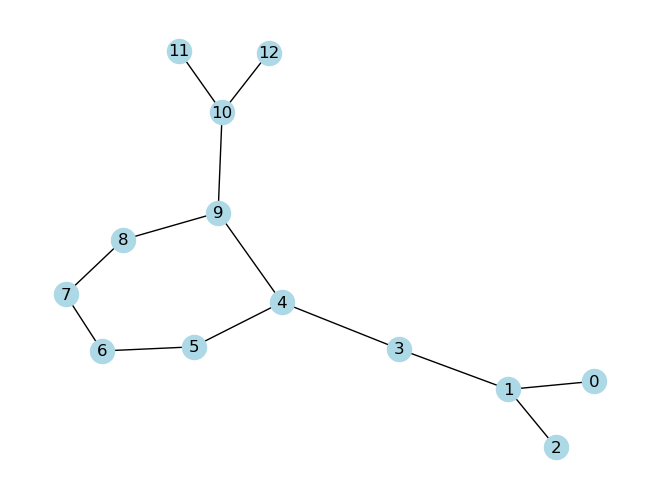

In [3]:
import datamol as dm
import networkx as nx
import matplotlib.pyplot as plt

mol = dm.to_mol(smi)
graph = dm.to_graph(mol)
pos = nx.spring_layout(graph)

nx.draw(graph, pos, with_labels=True, node_color='lightblue')
plt.show()

[Chemprop](https://github.com/chemprop/chemprop.git) is a python package that is used for Message Passing Neural Networks. It is commonly used for molecular graph models. There are several advantages to using the tool, such as a built in featurizer that will convert a smiles string into its representative graph. However, as of this writing, Chemprop does not include a method to visualize the molecular graphs.

In this example, a simple molecular graph can be generated, for [acetylsalicylic acid (aspirin 普拿疼)](https://en.wikipedia.org/wiki/Aspirin). Generating the length, we see that the number of graphical nodes (atoms) and the number of edge features (bonds) is 13. For molecular GNN message passing models, bidirectional edges are needed, i.e. an edge connecting A->B and an edge connecting B->A. In short, information needs to be passed from atom A to B and vice versa. This will give a total number of edges as 26 (number of atoms * 2).

In [1]:
from chemprop.featurizers import SimpleMoleculeMolGraphFeaturizer
from rdkit import Chem
smi = "CC(=O)OC1=CC=CC=C1C(=O)O"
mol = Chem.MolFromSmiles(smi)

feat = SimpleMoleculeMolGraphFeaturizer()
graph = feat(mol)

print(f'Number of atoms (Nodes): {len(graph.V)}')
print(f'Number of molecular bonds (edge features): {int(len(graph.E)/2)}')
print(f'Number of edges (bonds): {len(graph.E)}')

Number of atoms (Nodes): 13
Number of molecular bonds (edge features): 13
Number of edges (bonds): 26


There is a package called MMGX ([Github](https://github.com/ohuelab/MMGX.git), [Nature Communications Chemistry](https://www.nature.com/articles/s42004-024-01155-w)) that can be used ot generate a molecular graph and draw said graph in a 2D format. The code from MMGX has been adapted to this project, with enhancements made to the AtomGraph to include additional features not included in Chemprop's default SimpleMoleculeMolGraphFeaturizer().

**Note:** While the MMGX drawing modules have been wrapped, the molecular graph features have been modified. To get an idea of the constant values used for calculating the many types fo graph features in the module, this can be done by printing the GLOBAL_VALUES() method.

In [4]:
GLOBAL_VALUES()

ATOM Features: 142
  0: H
  1: He
  2: Li
  3: Be
  4: B
  5: C
  6: N
  7: O
  8: F
  9: Ne
  10: Na
  11: Mg
  12: Al
  13: Si
  14: P
  15: S
  16: Cl
  17: Ar
  18: K
  19: Ca
  20: Sc
  21: Ti
  22: V
  23: Cr
  24: Mn
  25: Fe
  26: Co
  27: Ni
  28: Cu
  29: Zn
  30: Ga
  31: Ge
  32: As
  33: Se
  34: Br
  35: Kr
  36: Rb
  37: Sr
  38: Y
  39: Zr
  40: Nb
  41: Mo
  42: Tc
  43: Ru
  44: Rh
  45: Pd
  46: Ag
  47: Cd
  48: In
  49: Sn
  50: Sb
  51: Te
  52: I
  53: Xe
  54: Cs
  55: Ba
  56: La
  57: Ce
  58: Pr
  59: Nd
  60: Pm
  61: Sm
  62: Eu
  63: Gd
  64: Tb
  65: Dy
  66: Ho
  67: Er
  68: Tm
  69: Yb
  70: Lu
  71: Hf
  72: Ta
  73: W
  74: Re
  75: Os
  76: Ir
  77: Pt
  78: Au
  79: Hg
  80: Tl
  81: Pb
  82: Bi
  83: Po
  84: At
  85: Rn
  86: Fr
  87: Ra
  88: Ac
  89: Th
  90: Pa
  91: U
  92: Np
  93: Pu
  94: Am
  95: Cm
  96: Bk
  97: Cf
  98: Es
  99: Fm
  Atom Degree: 11
  Atom Valence: 7
  Formal charge: 5
  Hybridization: 6
  Aromaticity: 1
  Number of Hy

The query molecule can be drawn from the smiles string for quick visualization. Here the molecule is drawn with atom index.

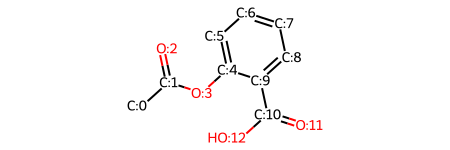

In [5]:
plot = Graph(smi=smi)
plot.get_mol(atom_index=True)

### AtomGraph

AtomGraph will generate a more "traditional" molecular graph, where each atom is a node and each bond is the edge. Printing the class will give the Molecule smiles string with the atoms labeled, and depending on the graph type, the Node Index, Edge Index, or Cliques. The Node Index denotes the number of nodes for the graph (for AtomGraph, this will be the number of atoms). The Edge Index denotes the bonds between each node and if cliques are available, the cliques will show bond groups.

The graph information should be ready for plug in into Deep Learning models.

In [6]:
graph = AtomGraph(smi=smi)
print(graph)

Molecule Graph: C[C:1](=[O:2])[O:3][c:4]1[cH:5][cH:6][cH:7][cH:8][c:9]1[C:10](=[O:11])[OH:12]
Node Index:[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Edge Index:[(0, 1), (1, 0), (1, 2), (2, 1), (1, 3), (3, 1), (3, 4), (4, 3), (4, 5), (5, 4), (5, 6), (6, 5), (6, 7), (7, 6), (7, 8), (8, 7), (8, 9), (9, 8), (9, 10), (10, 9), (10, 11), (11, 10), (10, 12), (12, 10), (9, 4), (4, 9)]


Note that the graph features can correspond to the following:

In [7]:
print(f'Number of graph nodes (atoms): {len(graph.node_features)}')
print(f'Number of molecular bonds: {int(len(graph.edge_index)/2)}')
print(f'Number of graph edges (bonds): {len(graph.edge_index)}')

Number of graph nodes (atoms): 13
Number of molecular bonds: 13
Number of graph edges (bonds): 26


Additionally, the graph nodes, edge, and edge index can be printed and double checked for length and values. Below is an example of outputting the length of the node features.

In [8]:
len(graph.node_features[0])

142

In [9]:
# graph.node_features[0]

Importantly, the molecular graphs can be drawn for visualization. This is done using the display_graph() method from the Graph() visualization class. The display_graph() accepts the generated graph information and will draw two images - the molecule and the graph. Additional params are available, such as color options, modification to title sizes or image size.

**Note:** Depending on the molcule, the size of the figure will need to be adjusted to properly "space" the graph nodes.

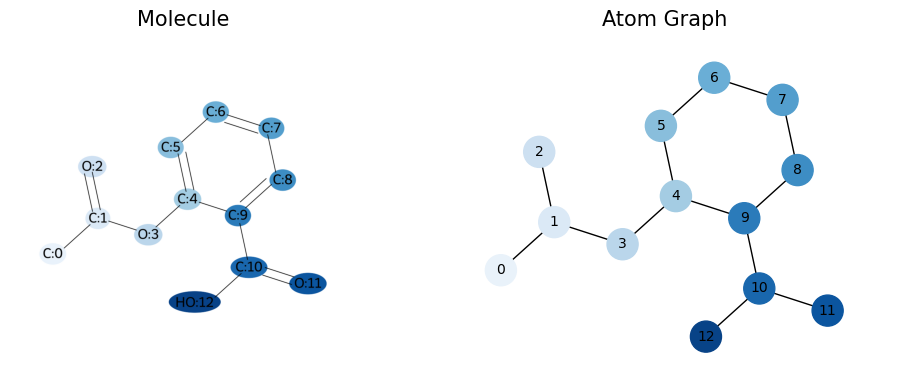

In [10]:
# plot.display_graph(graph, colors="Blues", graph_labels=True, figsize=(20,8))
plot.display_graph(graph, colors="Blues", graph_labels=True)

### PharmacophoreGraph
The class PharmacophoreGraph will generate a molecular graph based on the molecule pharmacophores. This is based on the cliques, which contains a list of atom indexes for each pharmacophore in the graph.

In [11]:
graph = PharmacophoreGraph(smi=smi)
print(graph)

Molecule Graph: C[C:1](=[O:2])[O:3][c:4]1[cH:5][cH:6][cH:7][cH:8][c:9]1[C:10](=[O:11])[OH:12]
Node Index:[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Edge Index:[(0, 1), (1, 0), (1, 2), (2, 1), (1, 3), (3, 1), (3, 4), (4, 3), (5, 6), (6, 5), (6, 7), (7, 6), (6, 8), (8, 6), (5, 4), (4, 5), (4, 9), (9, 4), (5, 9), (9, 5)]
Cliques:[[0], [1], [2], [3], [4], [9], [10], [11], [12], [4, 9, 8, 7, 6, 5]]


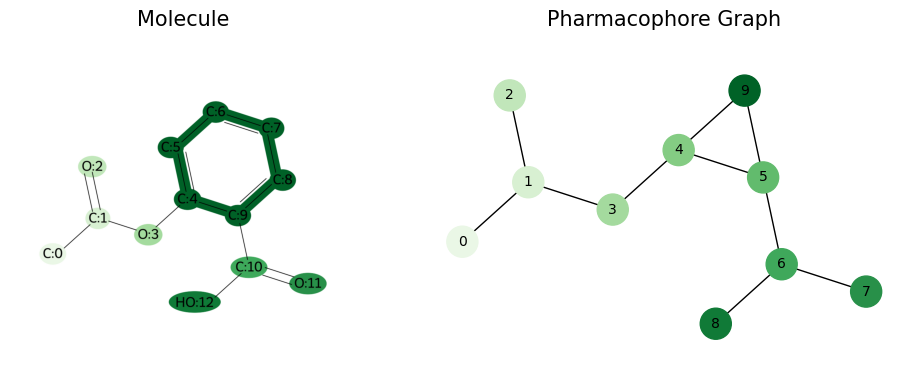

In [12]:
plot.display_graph(graph, colors="Greens", graph_labels=True)

### ClusterGraph
The class ClusterGraph generates a molecular graph by clustering the atom cliques. Each clique corresponds to rings or functional groups and will correspond to the graphical nodes.

In [13]:
graph = ClusterGraph(smi=smi)
print(graph)

Molecule Graph: C[C:1](=[O:2])[O:3][c:4]1[cH:5][cH:6][cH:7][cH:8][c:9]1[C:10](=[O:11])[OH:12]
Node Index:[0, 1, 2, 3, 4, 5, 6, 7]
Edge Index:[(0, 1), (1, 0), (0, 2), (2, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 7), (7, 3), (4, 7), (7, 4), (4, 5), (5, 4), (4, 6), (6, 4), (5, 6), (6, 5)]
Cliques:[[0, 1], [1, 2], [1, 3], [3, 4], [9, 10], [10, 11], [10, 12], [4, 9, 8, 7, 6, 5]]


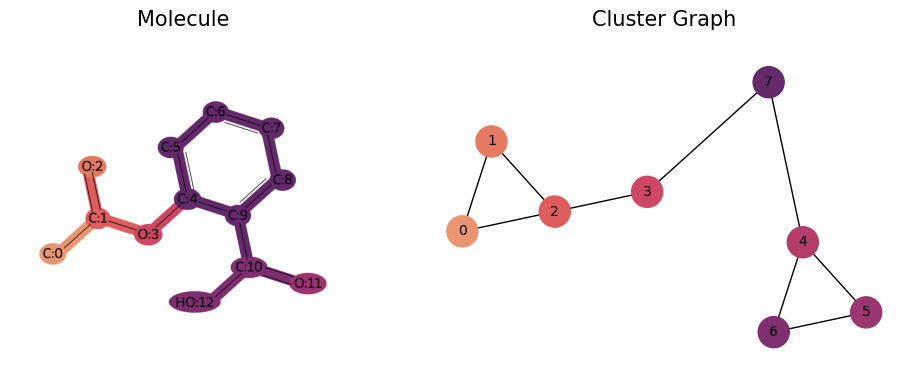

In [14]:
plot.display_graph(graph, colors="flare", graph_labels=True)

### FunctionalGraph
The class FunctionalGraph will generate a molecular graph based on the [RDKit FunctionalGroups](https://github.com/rdkit/rdkit/blob/master/Data/FunctionalGroups.txt).

In [15]:
graph = FunctionalGraph(smi=smi)
print(graph)

Molecule Graph: C[C:1](=[O:2])[O:3][c:4]1[cH:5][cH:6][cH:7][cH:8][c:9]1[C:10](=[O:11])[OH:12]
Node Index:[0, 1, 2, 3]
Edge Index:[(1, 2), (2, 1), (2, 3), (3, 2), (0, 3), (3, 0)]
Cliques:[[9, 10, 11, 12], [3, 1, 2, 0], [3, 4], [4, 9, 8, 7, 6, 5]]


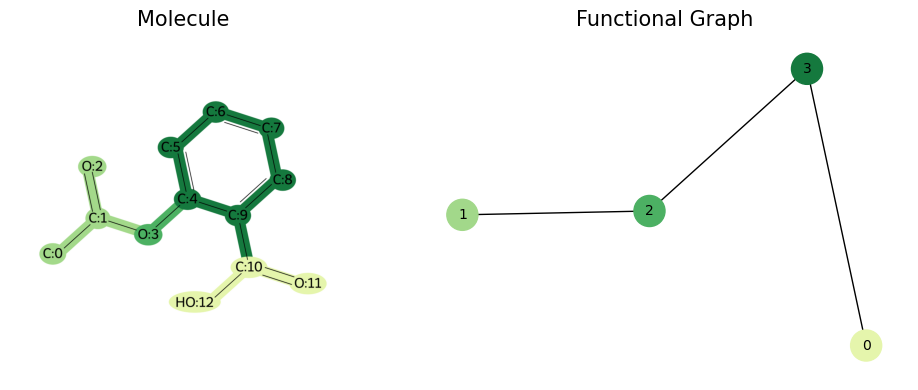

In [16]:
plot.display_graph(graph, colors="YlGn", graph_labels=True)

### JunctionTreeGraph
Finally, a molecular tree can be generated based on the Junction Tree. This seeks to reduce graphs by converting teh bonds, rings, and junction atoms into the graphical nodes.

In [17]:
graph = JunctionTreeGraph(smi=smi)
print(graph)

Molecule Graph: C[C:1](=[O:2])[O:3][c:4]1[cH:5][cH:6][cH:7][cH:8][c:9]1[C:10](=[O:11])[OH:12]
Node Index:[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Edge Index:[(0, 8), (8, 0), (1, 8), (8, 1), (2, 3), (3, 2), (2, 8), (8, 2), (3, 7), (7, 3), (4, 7), (7, 4), (4, 9), (9, 4), (5, 9), (9, 5), (6, 9), (9, 6)]
Cliques:[[0, 1], [1, 2], [1, 3], [3, 4], [9, 10], [10, 11], [10, 12], [4, 9, 8, 7, 6, 5], [1], [10]]


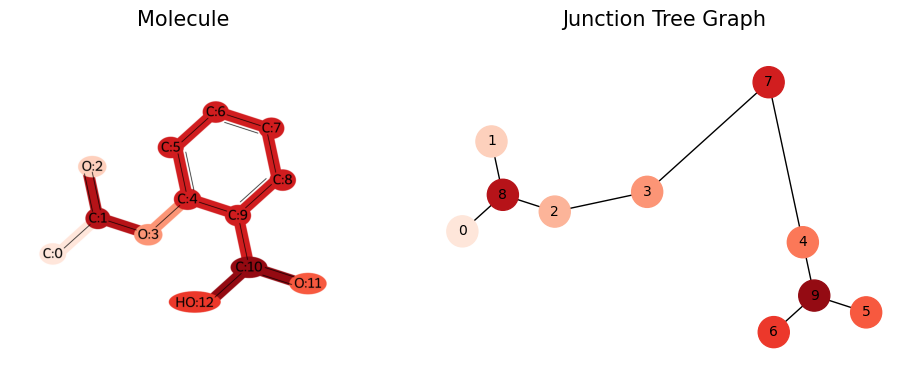

In [18]:
plot.display_graph(graph, colors="Reds", graph_labels=True)